NPTS from file : 1559
DT from file   : 0.02 sec
Data points    : 1568
PGA = 0.31882 g


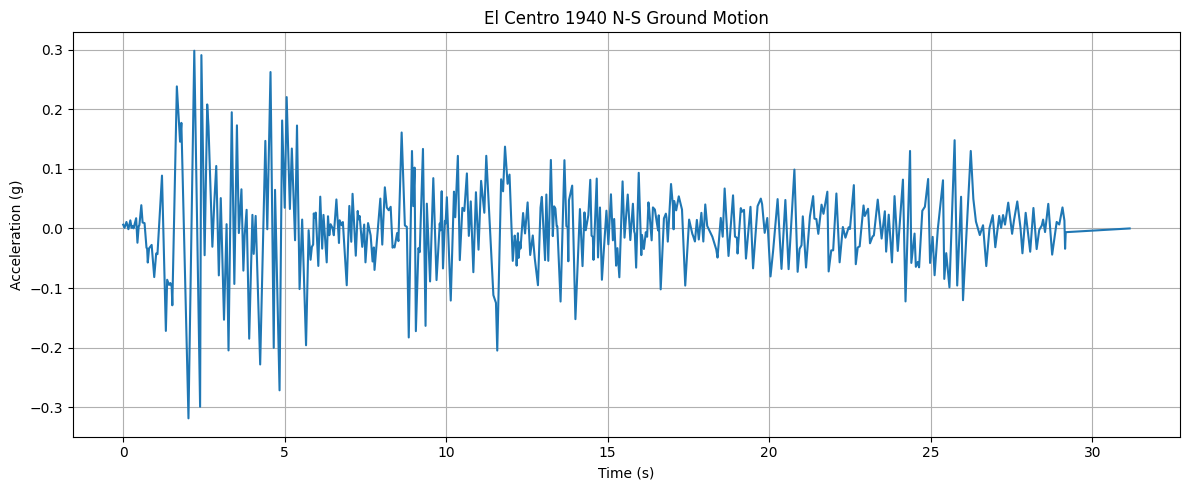

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

# ============================================================
# 1. File path
# ============================================================

file = r"C:\Disk E\old laptop file\opensees theory\theory about timehistory\elCentro (1).at2"

# ============================================================
# 2. Read the entire AT2 file
# ============================================================

with open(file, "r") as f:
    lines = f.readlines()

# ============================================================
# 3. Find NPTS and DT
# ============================================================

for i, line in enumerate(lines):

    if "NPTS=" in line:

        # Example:
        # NPTS= 1559, DT= .02000 SEC

        npts = int(
            re.search(r"NPTS=\s*(\d+)", line).group(1)
        )

        dt = float(
            re.search(r"DT=\s*([0-9.]+)", line).group(1)
        )

        # Acceleration data starts after this line
        data_start = i + 1

        break

# ============================================================
# 4. Read acceleration data using Pandas
# ============================================================

ground_motion = pd.read_csv(
    file,
    skiprows=data_start,
    header=None,
    sep=r"\s+"
)

# ============================================================
# 5. Convert multiple columns into one continuous series
# ============================================================

ground_motion = ground_motion.stack().reset_index(drop=True)

# Convert strings to numbers
ground_motion = pd.to_numeric(ground_motion, errors="coerce")

# ============================================================
# 6. Check number of points
# ============================================================

print("NPTS from file :", npts)
print("DT from file   :", dt, "sec")
print("Data points    :", len(ground_motion))

# ============================================================
# 7. Create time vector
# ============================================================

time = np.arange(len(ground_motion)) * dt

# ============================================================
# 8. Calculate PGA
# ============================================================

PGA = np.max(np.abs(ground_motion))

print("PGA =", PGA, "g")

# ============================================================
# 9. Plot earthquake ground motion
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(time, ground_motion)

plt.xlabel("Time (s)")
plt.ylabel("Acceleration (g)")
plt.title("El Centro 1940 N-S Ground Motion")

plt.grid(True)
plt.tight_layout()
plt.show()

In [2]:
# ============================================================
# 10. Create Excel file
# ============================================================

excel_data = pd.DataFrame({
    "Time (s)": time,
    "Acceleration (g)": ground_motion
})

# Save Excel file
output_file = r"C:\Disk E\ElCentro_Time_Acceleration.xlsx"

excel_data.to_excel(output_file, index=False)

print("Excel file saved successfully!")
print("Location:", output_file)


Excel file saved successfully!
Location: C:\Disk E\ElCentro_Time_Acceleration.xlsx


In [3]:
print(len(time))
print(len(ground_motion))

1568
1568
